<a href="https://colab.research.google.com/github/apurva28072005/NNDL/blob/main/NNDL_pr_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape of X: (9950, 50, 1)
Training data: (7960, 50, 1)
Testing data: (1990, 50, 1)


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 50, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 50, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50, 64)         │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 50, 1)          │            65 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 49,985 (195.25 KB)

 Trainable params: 49,985 (195.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 26s 83ms/step - loss: 0.0440 - val_loss: 0.0120
Epoch 2/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 18s 73ms/step - loss: 9.1159 - val_loss: 0.0315
Epoch 3/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 18s 72ms/step - loss: 0.0225 - val_loss: 0.0178
Epoch 4/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 20s 80ms/step - loss: 0.0138 - val_loss: 0.0109
Epoch 5/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 19s 72ms/step - loss: 0.0080 - val_loss: 0.0045
Epoch 6/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 19s 77ms/step - loss: 0.0035 - val_loss: 0.0029
Epoch 7/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 19s 75ms/step - loss: 0.0024 - val_loss: 0.0020
Epoch 8/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 18s 73ms/step - loss: 0.0014 - val_loss: 0.0012
Epoch 9/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 21s 75ms/step - loss: 0.0010 - val_loss: 8.4618e-04
Epoch 10/10
249/249 ━━━━━━━━━━━━━━━━━━━━ 18s 73ms/step - loss: 6.4530e-04 - val_loss: 5.2089e-04


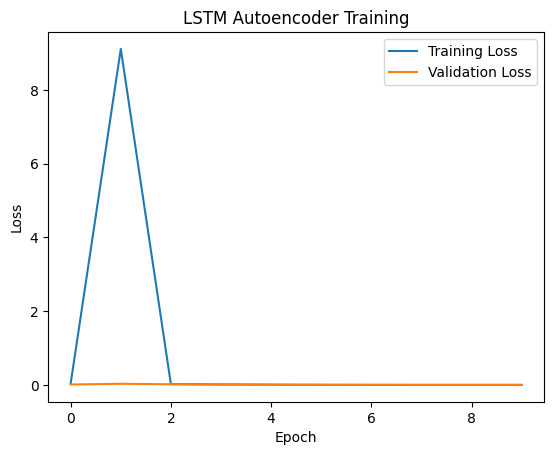

63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step
Original shape: (1990, 50, 1)
Reconstructed shape: (1990, 50, 1)


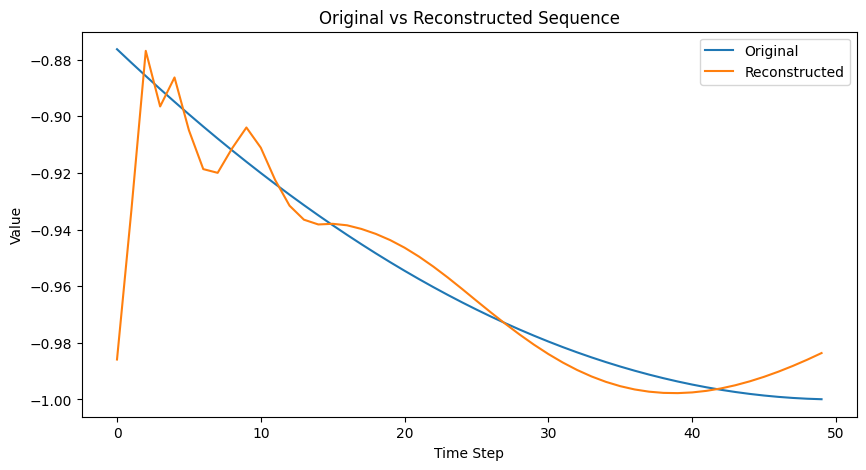

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, LSTM, RepeatVector, TimeDistributed, Dense

# Generate data
t = np.linspace(0, 100, 10000)
data = np.sin(t)

# Create sequences
sequence_length = 50
X = []

for i in range(len(data) - sequence_length):
    X.append(data[i:i + sequence_length])

X = np.array(X)

# Reshape for LSTM
X = X.reshape((X.shape[0], X.shape[1], 1))
print("Shape of X:", X.shape)

split = int(0.8 * len(X))
X_train = X[:split]
X_test = X[split:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

timesteps = X_train.shape[1]
features = X_train.shape[2]

# Input
inputs = Input(shape=(timesteps, features))

# Encoder
encoded = LSTM(64, activation='relu')(inputs)

# Repeat encoded vector
decoded = RepeatVector(timesteps)(encoded)

# Decoder
decoded = LSTM(64, activation='relu', return_sequences=True)(decoded)

# Output
outputs = TimeDistributed(Dense(features))(decoded)

# Model
model = Model(inputs, outputs)

model.compile(
    optimizer='adam',
    loss='mse'
)

model.summary()

history = model.fit(
    X_train,
    X_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_test, X_test)
)

# Plot Training Loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('LSTM Autoencoder Training')
plt.legend()
plt.show()

# Predict and compare reconstruction
X_pred = model.predict(X_test)

print("Original shape:", X_test.shape)
print("Reconstructed shape:", X_pred.shape)

plt.figure(figsize=(10, 5))
plt.plot(X_test[0].flatten(), label='Original')
plt.plot(X_pred[0].flatten(), label='Reconstructed')
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.title('Original vs Reconstructed Sequence')
plt.legend()
plt.show()
